#                          BURGER LAB PROJECT  STEPS

#  step 1:Business Problem


Burger Lab is pakistan Fastest  growing restaurent that is Fastly Growing in All Over
The Pakistan.The Restaurent is Actually want to open a Branch in A City  For that the company want
to have a complete Anaylsis of that area people that data is provided by the company and want to know the complete Data Anayltics Report of that data.

# step 2: DATA GATHERING

   the given data set is provided by the company itself that is Customer.csv file

DATA DICTIONARY:
   
CustomerID: string (nullable = true)
Genre: string (nullable = true)
Age: string (nullable = true)
Annual_Income_in_lac's: string (nullable = true)
Spending_on_Hotel'Food_in_thousand's_Annual: string (nullable = true)


# step 3: Analysis of Data generation

 As the dataset is given so we dont have to lookup to the data generation
 as its already in the single file.
   

#  step 4:Data Preprocessing and handling the Missing value

In this step we fetch the missing values and handle them .And convert data types,if we need.

# step 5:Data Aggregation and correlation

In this step we aggregate and find the correlation between the variables.

# step 6: Data visualization

In this step we visualize our data .

### IMPORTING DEPENDENCIES AND MODULES

In [ ]:
import pyspark
from pyspark.sql import SparkSession
import findspark
findspark.init()
from pyspark.sql.functions import isnan ,when ,count ,col
from pyspark.sql.functions import regexp_replace
from pyspark.sql import Window
from pyspark.sql.types import IntegerType
from pyspark.mllib.stat import Statistics
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [ ]:
#creating spark session
spark=SparkSession.builder.appName("BURGER LAB").getOrCreate()

In [ ]:
#reading the csv file using sparksession
df=spark.read.csv(r'C:\Users\Fariha\Desktop\Project\Data_customers.csv',header=True)

In [ ]:
df.show(4)#this line of code will show the first 4 records

+----------+-----+---+-------------+------------------+
|CustomerID|Genre|Age|Annual_Income|Resturant_Spending|
+----------+-----+---+-------------+------------------+
|         1|    1| 19|      1500000|             39000|
|         2|    1| 21|      1500000|             81000|
|         3|    0| 20|      1600000|              6000|
|         4|    0| 23|      1600000|             77000|
+----------+-----+---+-------------+------------------+
only showing top 4 rows



In [ ]:
df.printSchema()#this code will show the schema of the dataframe

root
 |-- CustomerID: string (nullable = true)
 |-- Genre: string (nullable = true)
 |-- Age: string (nullable = true)
 |-- Annual_Income: string (nullable = true)
 |-- Resturant_Spending: string (nullable = true)



In [ ]:
df.describe().show()#this method will describe our whole dataframe

+-------+------------------+------------------+-----------------+-----------------+------------------+
|summary|        CustomerID|             Genre|              Age|    Annual_Income|Resturant_Spending|
+-------+------------------+------------------+-----------------+-----------------+------------------+
|  count|               200|               200|              200|              200|               200|
|   mean|             100.5|              0.44|            38.85|        6056000.0|           50200.0|
| stddev|57.879184513951124|0.4976325863071808|13.96900733155888|2626472.116527126|25823.521668370173|
|    min|                 1|                 0|               18|         10100000|              1000|
|    max|                99|                 1|               70|          9900000|             99000|
+-------+------------------+------------------+-----------------+-----------------+------------------+



In [ ]:
#checking missing values in whole dataframe
df.select([count(when(isnan(c)|col(c).isNull(),c)).alias(c) for c in df.columns]).show()#as inthis dataframe have no missing or null values


+----------+-----+---+-------------+------------------+
|CustomerID|Genre|Age|Annual_Income|Resturant_Spending|
+----------+-----+---+-------------+------------------+
|         0|    0|  0|            0|                 0|
+----------+-----+---+-------------+------------------+



In [ ]:
#fetching missing values from one columns and show
df.where(col('Age').isNull()).show()

+----------+-----+---+-------------+------------------+
|CustomerID|Genre|Age|Annual_Income|Resturant_Spending|
+----------+-----+---+-------------+------------------+
+----------+-----+---+-------------+------------------+



In [ ]:
df.printSchema()

root
 |-- CustomerID: string (nullable = true)
 |-- Genre: string (nullable = true)
 |-- Age: string (nullable = true)
 |-- Annual_Income: string (nullable = true)
 |-- Resturant_Spending: string (nullable = true)



In [ ]:
df.withColumn('Genre',df.Genre.cast('int'))
df.withColumn('Age',df.Age.cast('int'))
df.withColumn('Annual_Income',df.Annual_Income.cast('int'))
df.withColumn('Resturant_Spending',df.Resturant_Spending.cast('int'))




DataFrame[CustomerID: string, Genre: string, Age: string, Annual_Income: string, Resturant_Spending: int]

In [ ]:
df.printSchema()

root
 |-- CustomerID: string (nullable = true)
 |-- Genre: string (nullable = true)
 |-- Age: string (nullable = true)
 |-- Annual_Income: string (nullable = true)
 |-- Resturant_Spending: string (nullable = true)



In [ ]:
df.groupBy('Genre').count().show()

+-----+-----+
|Genre|count|
+-----+-----+
|    0|  112|
|    1|   88|
+-----+-----+



In [ ]:
df.groupBy('Age').count().show()

+---+-----+
|Age|count|
+---+-----+
| 51|    2|
| 54|    4|
| 29|    5|
| 69|    1|
| 42|    2|
| 64|    1|
| 30|    7|
| 34|    5|
| 59|    4|
| 22|    3|
| 28|    4|
| 35|    9|
| 52|    2|
| 47|    6|
| 43|    3|
| 31|    8|
| 18|    4|
| 70|    2|
| 27|    6|
| 26|    2|
+---+-----+
only showing top 20 rows



In [ ]:
df.groupBy('Annual_Income').count().show()

+-------------+-----+
|Annual_Income|count|
+-------------+-----+
|      8800000|    4|
|      4300000|    4|
|      5900000|    2|
|      3400000|    2|
|     11300000|    2|
|      9900000|    2|
|      7500000|    2|
|      1500000|    2|
|      6900000|    2|
|      7300000|    4|
|      6100000|    2|
|      7000000|    2|
|      4200000|    2|
|      1700000|    2|
|      5400000|   12|
|      6000000|    6|
|      7200000|    2|
|      6700000|    4|
|     10300000|    4|
|      5700000|    2|
+-------------+-----+
only showing top 20 rows



In [ ]:
df.groupBy('Resturant_Spending').count().show()

+------------------+-----+
|Resturant_Spending|count|
+------------------+-----+
|             66000|    1|
|             14000|    4|
|             53000|    1|
|             81000|    2|
|             87000|    2|
|             79000|    2|
|             73000|    6|
|             11000|    1|
|             26000|    2|
|              5000|    4|
|             75000|    5|
|             82000|    1|
|             90000|    2|
|             49000|    3|
|             10000|    2|
|             56000|    4|
|             23000|    1|
|             36000|    2|
|              7000|    1|
|             13000|    3|
+------------------+-----+
only showing top 20 rows



In [ ]:
df=df.withColumn('Resturant_Spending',df['Resturant_Spending'].cast(IntegerType()))

In [ ]:
df.printSchema()

root
 |-- CustomerID: string (nullable = true)
 |-- Genre: string (nullable = true)
 |-- Age: string (nullable = true)
 |-- Annual_Income: string (nullable = true)
 |-- Resturant_Spending: integer (nullable = true)



In [ ]:
df=df.withColumn('CustomerID',df['CustomerID'].cast(IntegerType()))

In [ ]:
df.printSchema()

root
 |-- CustomerID: integer (nullable = true)
 |-- Genre: string (nullable = true)
 |-- Age: string (nullable = true)
 |-- Annual_Income: string (nullable = true)
 |-- Resturant_Spending: integer (nullable = true)



In [ ]:
df=df.withColumn('Genre',df['Genre'].cast(IntegerType()))

In [ ]:
df=df.withColumn('Age',df['Age'].cast(IntegerType()))

In [ ]:
df=df.withColumn('Annual_Income',df['Annual_Income'].cast(IntegerType()))

In [ ]:
df.printSchema()

root
 |-- CustomerID: integer (nullable = true)
 |-- Genre: integer (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Annual_Income: integer (nullable = true)
 |-- Resturant_Spending: integer (nullable = true)



In [ ]:
df.groupBy('Age').min('Annual_Income').show()

+---+------------------+
|Age|min(Annual_Income)|
+---+------------------+
| 31|           1700000|
| 65|           3800000|
| 53|           3300000|
| 34|           5800000|
| 28|           7600000|
| 27|           4000000|
| 26|           5400000|
| 44|           7300000|
| 22|           1700000|
| 47|           4300000|
| 52|           2300000|
| 20|           1600000|
| 40|           2900000|
| 57|           5400000|
| 54|           2800000|
| 48|           3900000|
| 19|           1500000|
| 64|           1900000|
| 41|           9900000|
| 43|           4800000|
+---+------------------+
only showing top 20 rows



In [ ]:
df.groupBy('Age').sum('Annual_Income').show()

+---+------------------+
|Age|sum(Annual_Income)|
+---+------------------+
| 31|          38700000|
| 65|          10100000|
| 53|           7900000|
| 34|          39500000|
| 28|          34100000|
| 27|          37900000|
| 26|          11600000|
| 44|          15100000|
| 22|           9400000|
| 47|          42100000|
| 52|          11100000|
| 20|          20800000|
| 40|          37000000|
| 57|          12900000|
| 54|          23900000|
| 48|          29100000|
| 19|          45600000|
| 64|           1900000|
| 41|          20200000|
| 43|          19700000|
+---+------------------+
only showing top 20 rows



In [ ]:
df.groupBy('Age').max('Annual_Income').show()

+---+------------------+
|Age|max(Annual_Income)|
+---+------------------+
| 31|           8100000|
| 65|           6300000|
| 53|           4600000|
| 34|          10300000|
| 28|          10100000|
| 27|           8800000|
| 26|           6200000|
| 44|           7800000|
| 22|           5700000|
| 47|          12000000|
| 52|           8800000|
| 20|           7300000|
| 40|           8700000|
| 57|           7500000|
| 54|          10100000|
| 48|           7700000|
| 19|           8100000|
| 64|           1900000|
| 41|          10300000|
| 43|           7800000|
+---+------------------+
only showing top 20 rows



In [ ]:
df.groupBy('genre').max('Age').show()

+-----+--------+
|genre|max(Age)|
+-----+--------+
|    1|      70|
|    0|      68|
+-----+--------+



In [ ]:
df.groupBy('genre').min('Age').show()

+-----+--------+
|genre|min(Age)|
+-----+--------+
|    1|      18|
|    0|      18|
+-----+--------+



In [ ]:
df1=df.groupBy('Age').max('Resturant_Spending').show()

+---+-----------------------+
|Age|max(Resturant_Spending)|
+---+-----------------------+
| 31|                  93000|
| 65|                  52000|
| 53|                  46000|
| 34|                  90000|
| 28|                  97000|
| 27|                  89000|
| 26|                  55000|
| 44|                  20000|
| 22|                  79000|
| 47|                  47000|
| 52|                  29000|
| 20|                  75000|
| 40|                  95000|
| 57|                  51000|
| 54|                  59000|
| 48|                  49000|
| 19|                  59000|
| 64|                   3000|
| 41|                  39000|
| 43|                  50000|
+---+-----------------------+
only showing top 20 rows



In [ ]:
df_Plot=df.groupBy('Age').min('Resturant_Spending').show()

+---+-----------------------+
|Age|min(Resturant_Spending)|
+---+-----------------------+
| 31|                  40000|
| 65|                  35000|
| 53|                   4000|
| 34|                   1000|
| 28|                  40000|
| 27|                  47000|
| 26|                  54000|
| 44|                   7000|
| 22|                  55000|
| 47|                   9000|
| 52|                  13000|
| 20|                   5000|
| 40|                  13000|
| 57|                   5000|
| 54|                  14000|
| 48|                  36000|
| 19|                   5000|
| 64|                   3000|
| 41|                  17000|
| 43|                  17000|
+---+-----------------------+
only showing top 20 rows



In [ ]:
df.corr('Age','Genre')


0.06086738703843336

In [ ]:
df.corr('Age','Annual_Income')

-0.012398042736060445

In [ ]:
df.corr('Annual_Income','Resturant_Spending')

0.00990284809403744

In [ ]:
df_1=df.select('CustomerID').toPandas()

In [ ]:
df_2=df.select('Genre').toPandas()

In [ ]:
df_3=df.select('Age').toPandas()

In [ ]:
df_4=df.select('Annual_Income').toPandas()

In [ ]:
df_5=df.select('Resturant_Spending').toPandas()

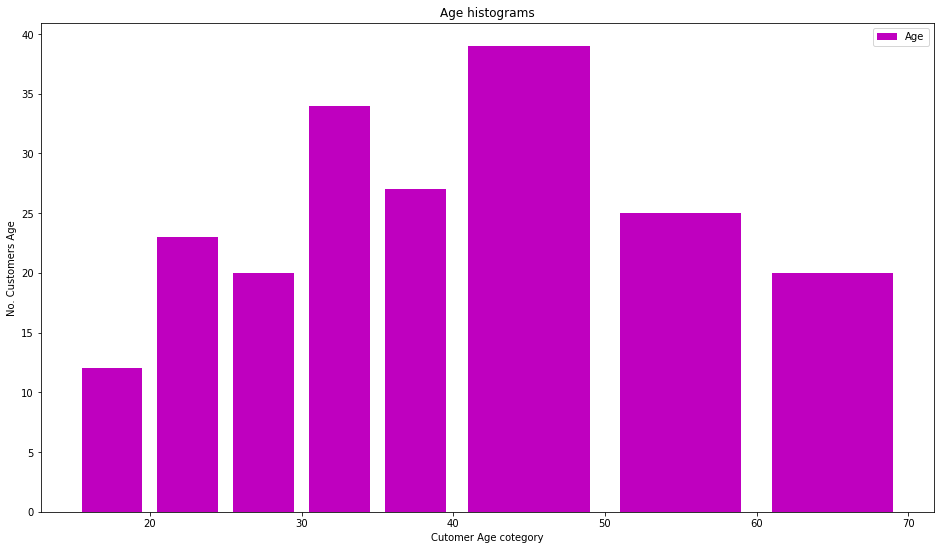

In [ ]:
bins = [15,20,25,30,35,40,50,60,70] # category of ML students age on x axis
plt.figure(figsize = (16,9))
plt.hist(df_3, bins, rwidth=0.8, histtype = "bar",
         orientation='vertical', color = "m", label = "Age")

plt.title("Age histograms")
plt.xlabel("Cutomer Age cotegory")
plt.ylabel("No. Customers Age")
plt.legend()
plt.show()

#Findings:
we have seen in the data the maximum customer age is between 40 to 50 years

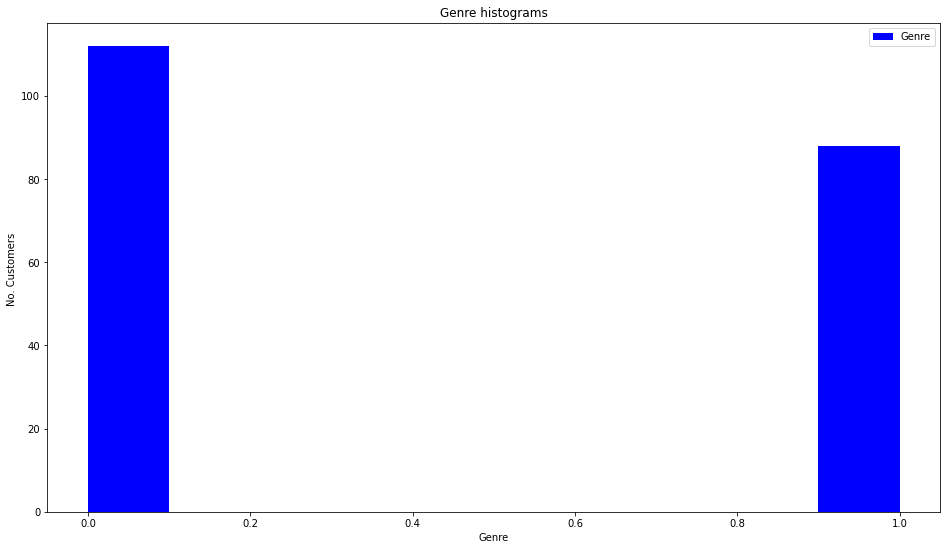

In [ ]:
 plt.figure(figsize = (16,9))
plt.hist(df_2, histtype = "bar",
         orientation='vertical', color = "b", label = "Genre")

plt.title("Genre histograms")
plt.xlabel("Genre")
plt.ylabel("No. Customers ")
plt.legend()
plt.show()

in data we have
o for Female =112
1 for  male = 88
so Female visited the Resturant more in this case

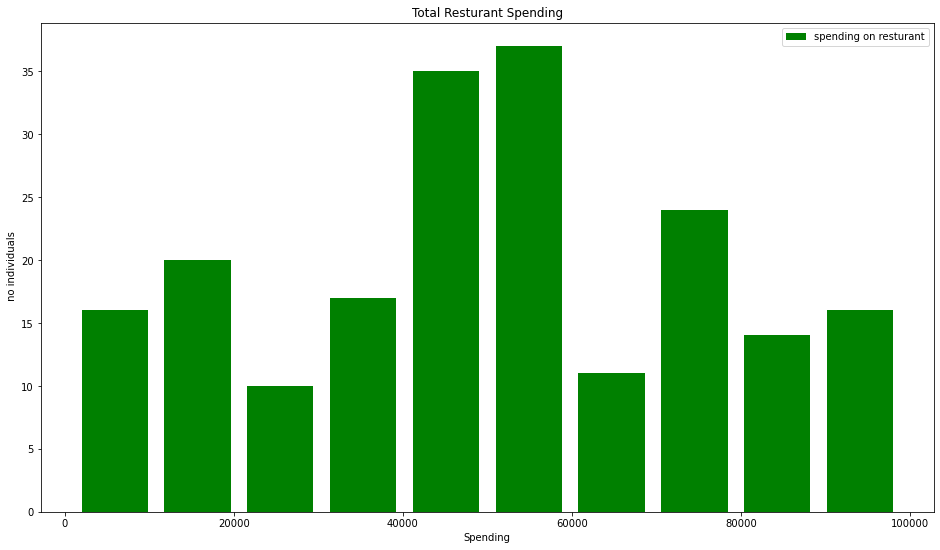

In [ ]:
plt.figure(figsize = (16,9))
plt.hist(df_5, histtype = "bar",
         orientation='vertical',rwidth=0.8, color = "g", label = "spending on resturant")

plt.title("Total Resturant Spending")
plt.xlabel("Spending")
plt.ylabel(" no individuals")
plt.legend()
plt.show()

Mostly we have spendings betweens 40000 to 60000 by many individuals

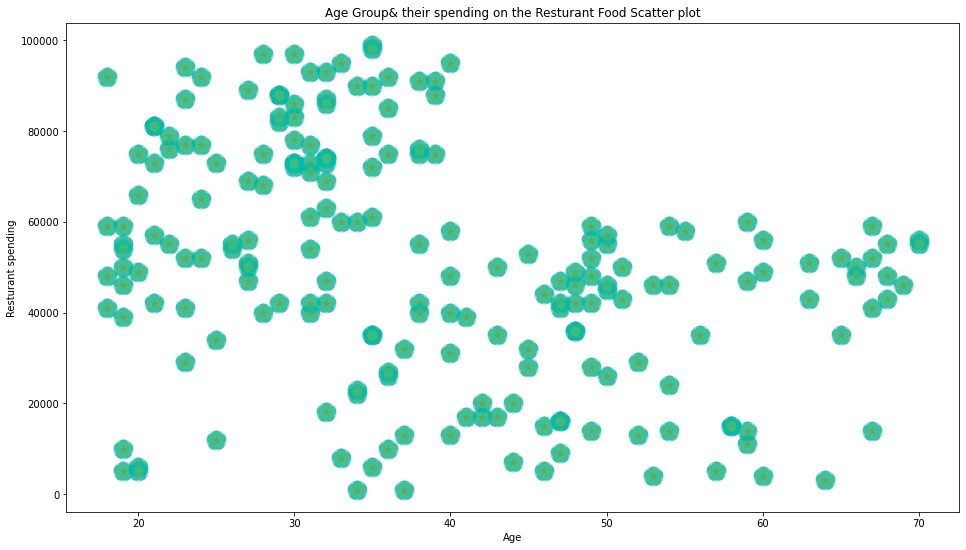

In [ ]:
plt.figure(figsize = (16,9))
plt.scatter(df_3,df_5, c = "r", marker = "*", s = 100, alpha=0.5, linewidths=10,
           edgecolors="g" )#verts="<"

plt.scatter(df_3,df_5, c = "y", marker = "o", s = 100, alpha=0.5, linewidths=10,
           edgecolors="c" )
plt.title("Age Group& their spending on the Resturant Food Scatter plot")
plt.xlabel("Age")
plt.ylabel("Resturant spending")
plt.show()


# we have seen that KPI Age and their Spending on Restaurant described in the  above  group mostly people that are young visited the most restaurant and the older the age visited the least restaurant But we suggested to open the restaurant here as the more are young people live in the town that visit's the Most Restaurant
